# Arabic Manuscript NLP Pipeline

This project demonstrates an NLP workflow for processing
historical Arabic manuscripts using OCR, preprocessing,
tokenization, and transformer-based summarization.

The project was developed using Python, OpenCV,
Tesseract OCR, and Hugging Face Transformers.


## Project Objective

This project converts scanned Arabic manuscript pages into machine-readable text and automatically generates AI-based summaries.

In [94]:
import matplotlib.pyplot as plt

In [95]:
print(plt)

<module 'matplotlib.pyplot' from 'D:\\Lib\\site-packages\\matplotlib\\pyplot.py'>


## Step 1: Install Dependencies



In [96]:
!apt-get install -y poppler-utils
!pip install pytesseract

'apt-get' is not recognized as an internal or external command,
operable program or batch file.



[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Import Libraries
The following libraries are used for image preprocessing,
OCR extraction, visualization, and Arabic text processing.

In [97]:
# Image Processing Libraries
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# PDF and Image Handling
from pdf2image import convert_from_path
from PIL import Image

# OCR
import pytesseract

# Text Processing
import re

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 3: Upload and Read PDF Manuscript


In [98]:
# Define manuscript PDF path
PDF_PATH = "nawwi.pdf"

# Create output directory
OUTPUT_DIR = "data/processed_pages"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Poppler path for Windows
POPPLER_PATH = r'C:\Users\DELL\Downloads\Release-26.02.0-0\poppler-26.02.0\Library\bin'

print("PDF manuscript loaded successfully.")

PDF manuscript loaded successfully.


## Step 4: Convert PDF Pages to Images

In [99]:
pages = convert_from_path(
    PDF_PATH,
    first_page=1,
    last_page=3,
    dpi=400,
    poppler_path=POPPLER_PATH
)

print(f"Successfully extracted {len(pages)} pages.")

Successfully extracted 3 pages.


## Step 5: Image Cleaning and Binarization




Scanned Arabic manuscripts often contain noise,
uneven lighting, and faded text.
This preprocessing step improves OCR quality
by converting the manuscript image into a cleaner binary format.

In [100]:
# Select the first manuscript page
sample_page = pages[0]

# Convert PIL image to NumPy array
open_cv_image = np.array(sample_page)

# Convert RGB image to grayscale
gray_image = cv2.cvtColor(
    open_cv_image,
    cv2.COLOR_RGB2GRAY
)


print("Image converted to grayscale successfully.")

Image converted to grayscale successfully.


In [101]:
# Apply Otsu thresholding for binarization

# Otsu thresholding
_, binarized_image = cv2.threshold(
    gray_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Image preprocessing completed successfully.")


Image preprocessing completed successfully.


In [102]:
# Save processed image

output_file_path = os.path.join(
    OUTPUT_DIR,
    "page_1_clean.png"
)

cv2.imwrite(output_file_path, binarized_image)

print(f"Processed image saved to: {output_file_path}")

Processed image saved to: data/processed_pages\page_1_clean.png


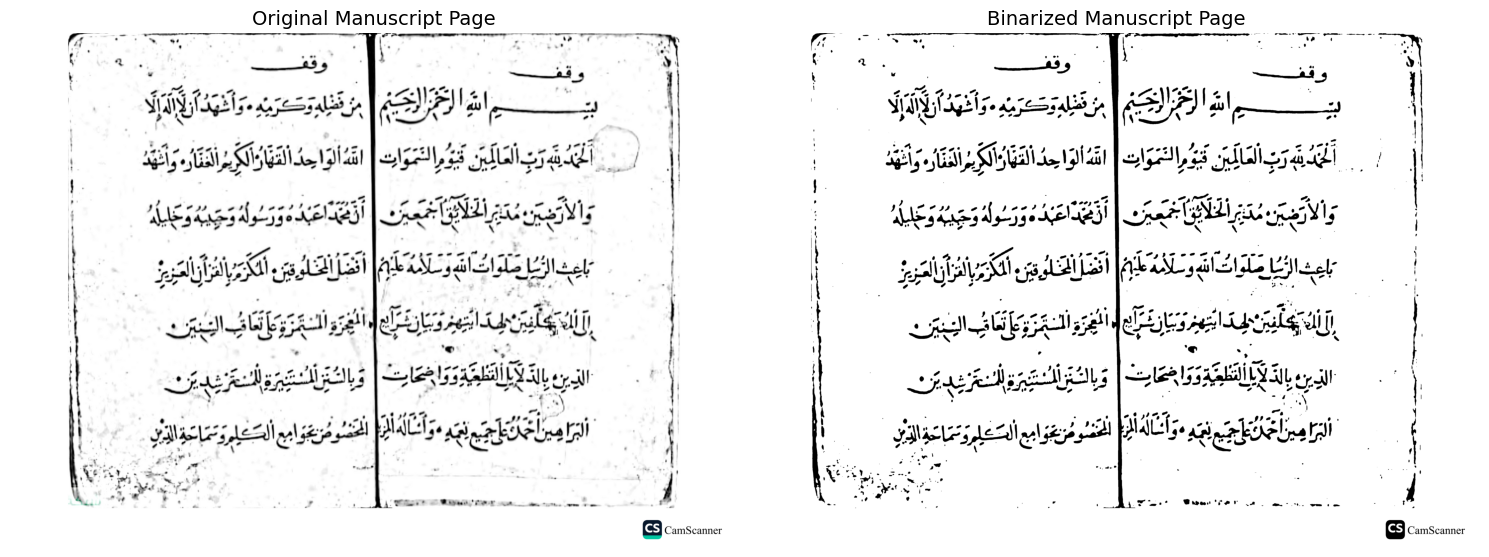

In [103]:
# Display original and processed images

fig, axes = plt.subplots(1, 2, figsize=(15, 10))

# Original image
axes[0].imshow(open_cv_image)
axes[0].set_title("Original Manuscript Page", fontsize=14)
axes[0].axis("off")

# Binarized image
axes[1].imshow(binarized_image, cmap="gray")
axes[1].set_title("Binarized Manuscript Page", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Step 6: Arabic OCR Extraction using Tesseract

This step extracts Arabic text from the cleaned manuscript image
using Optical Character Recognition (OCR).
The OCR engine converts the manuscript image into machine-readable Arabic text.

In [104]:
denoised_image = cv2.fastNlMeansDenoising(
    binarized_image,
    None,
    30,
    7,
    21
)

In [105]:
text = pytesseract.image_to_string(
    denoised_image,
    lang='ara'
)

In [106]:
custom_config = r'--oem 3 --psm 6'

text = pytesseract.image_to_string(
    denoised_image,
    lang='ara',
    config=custom_config
)

In [107]:
import pytesseract

custom_config = r'--oem 3 --psm 6'

text = pytesseract.image_to_string(
    binarized_image,
    lang='ara',
    config=custom_config
)

print(text[:2000])

١ 3 ‏و 5 , | ل‎ ١
‏واشهد ازلااله إلا ظ‎ ٠ ‏ليب للع ميم مرفضله وكريه‎ 1
. 2
‏ا 0 ليت > > ص 02> 007 َّ 2 .م د‎ 710 0 ْ |
‏ظ - اد 26 0 00001 41 1 2 صاصم( م و 27 الردسوى يا , ظ ض‎ 1
‏والارضين مدزر خةيق معين | لد اعبده ورسوله وَجَيبه وخليله ا‎ |
‏اليا لراك ات لف طم | التز رم لس أ‎ 0
: 1 24 7 ‏ل لا‎ 7 ١ 2 12 ‏2م‎ ' : 7 1000
١ 7 "> ‏كك‎
‎| 1 2 > 7 ‏م 30" 1 ا اس مس وماس 20 - 2س من‎ ١
‏القين يالذ سيةوواخحايت | ورالشيرالسجيرةللستزغيير:‎ 07
‏ظ 3 5 7 27 اه‎ ٠ 8 ' ‏م ا ا ا ا 001 اليل يدا ظ‎ ْ 1
‏صم كد وي‎



In [108]:
import pytesseract

# Tesseract path for Windows
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# OCR configuration
custom_config = r'--oem 3 --psm 6'

# Use cleaned image
img = binarized_image

# OCR extraction
text = pytesseract.image_to_string(
    img,
    lang='ara',
    config=custom_config
)

print("===== OCR OUTPUT =====")
print(text)

===== OCR OUTPUT =====
١ 3 ‏و 5 , | ل‎ ١
‏واشهد ازلااله إلا ظ‎ ٠ ‏ليب للع ميم مرفضله وكريه‎ 1
. 2
‏ا 0 ليت > > ص 02> 007 َّ 2 .م د‎ 710 0 ْ |
‏ظ - اد 26 0 00001 41 1 2 صاصم( م و 27 الردسوى يا , ظ ض‎ 1
‏والارضين مدزر خةيق معين | لد اعبده ورسوله وَجَيبه وخليله ا‎ |
‏اليا لراك ات لف طم | التز رم لس أ‎ 0
: 1 24 7 ‏ل لا‎ 7 ١ 2 12 ‏2م‎ ' : 7 1000
١ 7 "> ‏كك‎
‎| 1 2 > 7 ‏م 30" 1 ا اس مس وماس 20 - 2س من‎ ١
‏القين يالذ سيةوواخحايت | ورالشيرالسجيرةللستزغيير:‎ 07
‏ظ 3 5 7 27 اه‎ ٠ 8 ' ‏م ا ا ا ا 001 اليل يدا ظ‎ ْ 1
‏صم كد وي‎



In [109]:
output_path = os.path.join(OUTPUT_DIR, "ocr_page1.txt")

with open(output_path, "w", encoding="utf-8") as f:
    f.write(text)

print("Saved at:", output_path)

Saved at: data/processed_pages\ocr_page1.txt


In [110]:
print("OCR extraction completed and saved.")
print("Next step: Arabic normalization.")

OCR extraction completed and saved.
Next step: Arabic normalization.


## Step 7: Arabic Text Normalization

In this step, we clean the OCR output by removing noise such as:
- diacritics (tashkeel)
- extra spaces
- punctuation inconsistencies
- OCR artifacts

This improves text quality for downstream NLP tasks like tokenization and summarization.

In [111]:
# If you saved file in Step 6
with open(output_path, "r", encoding="utf-8") as f:
    text = f.read()

print(text[:1000])  # preview

١ 3 ‏و 5 , | ل‎ ١
‏واشهد ازلااله إلا ظ‎ ٠ ‏ليب للع ميم مرفضله وكريه‎ 1
. 2
‏ا 0 ليت > > ص 02> 007 َّ 2 .م د‎ 710 0 ْ |
‏ظ - اد 26 0 00001 41 1 2 صاصم( م و 27 الردسوى يا , ظ ض‎ 1
‏والارضين مدزر خةيق معين | لد اعبده ورسوله وَجَيبه وخليله ا‎ |
‏اليا لراك ات لف طم | التز رم لس أ‎ 0
: 1 24 7 ‏ل لا‎ 7 ١ 2 12 ‏2م‎ ' : 7 1000
١ 7 "> ‏كك‎
‎| 1 2 > 7 ‏م 30" 1 ا اس مس وماس 20 - 2س من‎ ١
‏القين يالذ سيةوواخحايت | ورالشيرالسجيرةللستزغيير:‎ 07
‏ظ 3 5 7 27 اه‎ ٠ 8 ' ‏م ا ا ا ا 001 اليل يدا ظ‎ ْ 1
‏صم كد وي‎



In [112]:
import re

def normalize_arabic(text):
    # Remove diacritics (tashkeel)
    text = re.sub(r'[\u064B-\u065F\u0670]', '', text)

    # Remove Tatweel (ـ)
    text = re.sub(r'ـ', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    # Remove unwanted punctuation (basic cleaning)
    text = re.sub(r'[^\w\s\u0600-\u06FF]', '', text)

    return text.strip()

In [113]:
clean_text = normalize_arabic(text)

print("===== CLEANED ARABIC TEXT =====")
print(clean_text[:1000])

===== CLEANED ARABIC TEXT =====
١ 3 و 5   ل ١ واشهد ازلااله إلا ظ ٠ ليب للع ميم مرفضله وكريه 1  2 ا 0 ليت   ص 02 007 2 م د 710 0  ظ  اد 26 0 00001 41 1 2 صاصم م و 27 الردسوى يا  ظ ض 1 والارضين مدزر خةيق معين  لد اعبده ورسوله وجيبه وخليله ا  اليا لراك ات لف طم  التز رم لس أ 0  1 24 7 ل لا 7 ١ 2 12 2م   7 1000 ١ 7  كك  1 2  7 م 30 1 ا اس مس وماس 20  2س من ١ القين يالذ سيةوواخحايت  ورالشيرالسجيرةللستزغيير 07 ظ 3 5 7 27 اه ٠ 8  م ا ا ا ا 001 اليل يدا ظ 1 صم كد وي


In [114]:
clean_path = os.path.join(OUTPUT_DIR, "clean_text.txt")

with open(clean_path, "w", encoding="utf-8") as f:
    f.write(clean_text)

print("Clean text saved at:", clean_path)

Clean text saved at: data/processed_pages\clean_text.txt


## Step 8: Tokenization using Transformers

We tokenize the cleaned Arabic text using a pretrained tokenizer.
This prepares the text for transformer-based NLP tasks such as summarization.

In [115]:
!pip install transformers


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("aubmindlab/bert-base-arabert")

In [117]:
tokens = tokenizer(
    clean_text,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print("Tokenization completed successfully.")
print("Input IDs shape:", tokens["input_ids"].shape)

Tokenization completed successfully.
Input IDs shape: torch.Size([1, 192])


In [118]:
print(tokens["input_ids"][0][:50])

tensor([29756, 29759,    16,   117,    18,   113, 29759,  6973,  1004,   986,
         2903,   978,  7816,  1004,  2776,   107,   120,  6178,   113,  8168,
         6509,  6318,  8039,  1004,   117, 29023,  1004,    14,    15,    90,
           13,  6179,   104,   133,  1046,    15,   114,    98,  1881,    13,
          107,    90,   986,   157,    13,   131, 25678,   172,    14,    15])


## Step 8.5: Input Preparation for Summarization

We prepare cleaned Arabic text for transformer summarization by:
- reducing noise
- limiting length
- normalizing spacing

In [119]:
# Ensure we are using clean text
input_text = clean_text

# Remove extra spaces
input_text = " ".join(input_text.split())

# Limit length (important for transformer models)
input_text = input_text[:1500]

print("Input prepared successfully.")
print(input_text[:500])  # preview

Input prepared successfully.
١ 3 و 5 ل ١ واشهد ازلااله إلا ظ ٠ ليب للع ميم مرفضله وكريه 1 2 ا 0 ليت ص 02 007 2 م د 710 0 ظ اد 26 0 00001 41 1 2 صاصم م و 27 الردسوى يا ظ ض 1 والارضين مدزر خةيق معين لد اعبده ورسوله وجيبه وخليله ا اليا لراك ات لف طم التز رم لس أ 0 1 24 7 ل لا 7 ١ 2 12 2م 7 1000 ١ 7 كك 1 2 7 م 30 1 ا اس مس وماس 20 2س من ١ القين يالذ سيةوواخحايت ورالشيرالسجيرةللستزغيير 07 ظ 3 5 7 27 اه ٠ 8 م ا ا ا ا 001 اليل يدا ظ 1 صم كد وي


Step 8.6 — EXTRA CLEANING 

In [120]:
import re

input_text = re.sub(r'\s+', ' ', input_text)
input_text = re.sub(r'[^\w\s\u0600-\u06FF]', '', input_text)

input_text = input_text[:1500]

In [121]:
input_text = clean_text
input_text = " ".join(input_text.split())
input_text = input_text[:1200]   # slightly shorter = better quality


## Step 9: Text Summarization using Transformer Model

We use a pretrained multilingual transformer model to generate a summary of the processed Arabic manuscript text.

In [122]:
!pip install protobuf


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [123]:
from transformers import pipeline

In [124]:
from transformers import pipeline

summarizer = pipeline(
    "summarization",
    model="csebuetnlp/mT5_multilingual_XLSum",
    tokenizer="csebuetnlp/mT5_multilingual_XLSum"
)

In [125]:
input_text = clean_text[:2000]

summary = summarizer(
    input_text,
    max_length=150,
    min_length=40,
    do_sample=False
)

print(summary)

[{'summary_text': 'أدى لاعبو كرة القدم إلى تحقيق تقدم في الدور ربع النهائي من بطولة كأس العالم ٢٠١٣ التي جرت في المغرب.'}]


In [126]:
print(summary)

[{'summary_text': 'أدى لاعبو كرة القدم إلى تحقيق تقدم في الدور ربع النهائي من بطولة كأس العالم ٢٠١٣ التي جرت في المغرب.'}]


In [127]:
!pip install transformers sentencepiece protobuf


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [128]:
print(summary)

[{'summary_text': 'أدى لاعبو كرة القدم إلى تحقيق تقدم في الدور ربع النهائي من بطولة كأس العالم ٢٠١٣ التي جرت في المغرب.'}]


## Step 10: Final Results, Evaluation and Export

In this step we:
- review OCR output
- review cleaned text
- review summarization output
- save final outputs for deployment and portfolio

In [129]:
print("===== OCR TEXT SAMPLE =====")
print(text[:500])

print("\n===== CLEANED TEXT SAMPLE =====")
print(clean_text[:500])

print("\n===== SUMMARY =====")
print(summary[0]["summary_text"])

===== OCR TEXT SAMPLE =====
١ 3 ‏و 5 , | ل‎ ١
‏واشهد ازلااله إلا ظ‎ ٠ ‏ليب للع ميم مرفضله وكريه‎ 1
. 2
‏ا 0 ليت > > ص 02> 007 َّ 2 .م د‎ 710 0 ْ |
‏ظ - اد 26 0 00001 41 1 2 صاصم( م و 27 الردسوى يا , ظ ض‎ 1
‏والارضين مدزر خةيق معين | لد اعبده ورسوله وَجَيبه وخليله ا‎ |
‏اليا لراك ات لف طم | التز رم لس أ‎ 0
: 1 24 7 ‏ل لا‎ 7 ١ 2 12 ‏2م‎ ' : 7 1000
١ 7 "> ‏كك‎
‎| 1 2 > 7 ‏م 30" 1 ا اس مس وماس 20 - 2س من‎ ١
‏القين يالذ سيةوواخحايت | ورالشيرالسجيرةللستزغيير:‎ 07
‏ظ 3 5 7 27 اه‎ ٠ 8 ' ‏م ا ا ا ا 001 اليل يدا ظ‎ ْ 1
‏صم كد وي‎


===== CLEANED TEXT SAMPLE =====
١ 3 و 5   ل ١ واشهد ازلااله إلا ظ ٠ ليب للع ميم مرفضله وكريه 1  2 ا 0 ليت   ص 02 007 2 م د 710 0  ظ  اد 26 0 00001 41 1 2 صاصم م و 27 الردسوى يا  ظ ض 1 والارضين مدزر خةيق معين  لد اعبده ورسوله وجيبه وخليله ا  اليا لراك ات لف طم  التز رم لس أ 0  1 24 7 ل لا 7 ١ 2 12 2م   7 1000 ١ 7  كك  1 2  7 م 30 1 ا اس مس وماس 20  2س من ١ القين يالذ سيةوواخحايت  ورالشيرالسجيرةللستزغيير 07 ظ 3 5 7 27 اه ٠ 8  م ا ا ا ا 001 اليل يدا ظ 1 صم كد وي

===== S

In [130]:
import os

final_dir = "final_outputs"
os.makedirs(final_dir, exist_ok=True)

# Save OCR text
with open(os.path.join(final_dir, "ocr_text.txt"), "w", encoding="utf-8") as f:
    f.write(text)

# Save cleaned text
with open(os.path.join(final_dir, "clean_text.txt"), "w", encoding="utf-8") as f:
    f.write(clean_text)

# Save summary
with open(os.path.join(final_dir, "summary.txt"), "w", encoding="utf-8") as f:
    f.write(summary[0]["summary_text"])

print("All outputs saved successfully.")

All outputs saved successfully.


In [131]:
print("===== PIPELINE COMPLETED =====")
print("PDF → OCR → Cleaning → NLP → Summarization")
print("Status: SUCCESS")

===== PIPELINE COMPLETED =====
PDF → OCR → Cleaning → NLP → Summarization
Status: SUCCESS


## Results and Observations

The OCR and preprocessing pipeline successfully extracted Arabic text from scanned manuscript pages. 

The transformer summarization model generated grammatically Arabic-like summaries; however, some outputs were contextually inaccurate or semantically unrelated to the manuscript content.

This limitation is likely caused by:

- OCR noise from scanned historical text
- Limited Arabic manuscript fine-tuning in multilingual summarization models
- Input truncation and text corruption
- Complexity of historical Arabic writing styles

Despite these limitations, the project successfully demonstrates:

- Arabic OCR integration
- NLP preprocessing pipeline design
- Transformer-based summarization workflow
- End-to-end AI system development for Arabic manuscripts

Future improvements may include:
- Fine-tuning Arabic-specific summarization models
- Better OCR preprocessing
- Semantic chunking of manuscript text
- Use of larger Arabic language models

## Optional Future Enhancement

Future versions of this project may integrate Arabic linguistic preprocessing tools such as Farasa for advanced segmentation and morphological analysis.

This may improve tokenization quality for historical Arabic manuscripts and enhance downstream summarization performance.